# The VLM backbone of a VLA, step by step 👁️🗣️
### Vision encoders, the language backbone, and where the two meet

**Code:** `src/Halo_VLA/vla_foundations/` (`encoders.py`, `probes.py`, `fusion.py`, `autoregressive.py`, `tasks.py`) on top of `open_vlas` ·
**papers:** SigLIP ([arXiv:2303.15343](https://arxiv.org/abs/2303.15343)), DINOv2 ([2304.07193](https://arxiv.org/abs/2304.07193)), RT-2 ([2307.15818](https://arxiv.org/abs/2307.15818)), OpenVLA ([2406.09246](https://arxiv.org/abs/2406.09246)),
π0 ([2410.24164](https://arxiv.org/abs/2410.24164)).

Every VLA is built on a **vision-language model**: *vision encoder(s)* → *projector* → *language backbone (an LLM)*, with the action head on top. This notebook takes that stack apart and asks, with experiments in a toy world, the three
questions that decide how such a model is built:

| part | question | experiment |
|---|---|---|
| 1 | **Which vision encoder?** language-supervised (SigLIP) vs self-supervised (DINOv2), or both fused (OpenVLA) | pre-train both from scratch, look inside, then plug them into a policy, *frozen*, and test them under a visual shift |
| 2 | **What does the language backbone provide?** and must it stay large? | RT-2's recipe: from scratch vs fine-tune vs **co-fine-tune**, at three sizes, tested on instructions the robot data never used |
| 3 | **Where do vision and language meet?** early vs late vs pooled fusion | the same action expert reads the three kinds of fused features on two task families |

### Where this notebook corrects the usual summary
* **π0 does not use PaLI-X's vision tower.** π0 initialises from **PaliGemma** (SigLIP + Gemma 2B). **RT-2** is built on **PaLI-X** (ViT-22B, 5B and 55B) and **PaLM-E-12B** (ViT-4B). **OpenVLA** fuses **DINOv2 + SigLIP** with a Llama 2 7B.
* **SigLIP's paper claim is the sigmoid loss** (a pairwise binary loss that scales to huge batches and works at small ones), not superiority on *dense spatial* tasks. The spatial strength comes from **DINOv2**, which is why OpenVLA (following the
  Prismatic study) *fuses* the two: *"improved spatial reasoning capabilities afforded by the fused SigLIP-DinoV2 backbones"*.
* **RT-2's 5B-vs-55B comparison is not "marginal gains".** Its Table 6 (generalisation, average): **5B from scratch 9, 5B fine-tune 42, 5B co-fine-tune 44; 55B fine-tune 52, 55B co-fine-tune 63.** Pre-training matters most, co-fine-tuning beats
  fine-tuning, and size gives a further, clear gain.

| | published | this notebook |
|---|---|---|
| vision | SigLIP So400m, DINOv2 ViT-L, ViT-22B | one small ViT (64 tokens), pre-trained from scratch two ways |
| language backbone | Llama 2 7B, Gemma 2B, PaLI-X 5B/55B | 3-6 layer transformers (62K-674K parameters) |
| pre-training data | web-scale image-text, 142M... robot episodes | rendered scenes with captions / VQA / synonyms |
| evaluation | real robots | closed loop in a 2-D point world |

> One seed, 96 scenes per number: read gaps of a few points as noise, large effects as real. Total runtime is about 45 minutes on a laptop CPU.

## Step 0: Setup, and the two task families

The point world again. Two instruction families, both with three objects (one of each colour):

* **`go to <colour>`**: bind a colour *word* to an object (language grounding);
* **`go to <left|right|top|bottom>`**: pick the object at an extreme of the scene: a *spatial relation between objects* (no colour is named).

The policy is the same flow-matching action expert as in the other notebooks; only the part that produces its conditioning features changes.

3000 colour demos, 3000 side demos


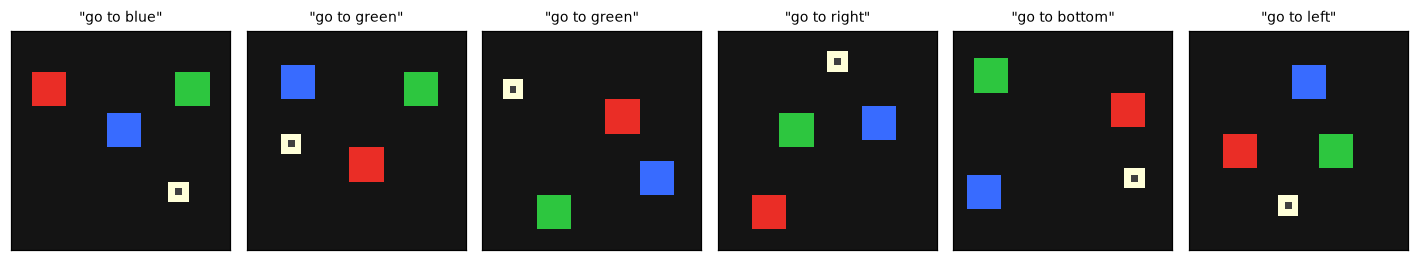

In [1]:
import copy, time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots, diagrams as dg

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, ToyVLM, VLMConfig, VLMPretrainer)
from pi_family import PiTrainer, PiVocabulary
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.autoregressive import ARConfig, AutoregressiveActionPolicy, make_cofine_tune_data
from vla_foundations.encoders import DinoLite, SigLIPLite, ToyViT, caption_vocab, scene_caption, train_dino, train_siglip
from vla_foundations.analysis import attention_breakdown, word_to_image_attention
from vla_foundations.fusion import FusedVision, FusionConfig, FusionPolicy
from vla_foundations.probes import semantic_probe, zero_shot_colors
from vla_foundations.tasks import (colour_scenarios_three, make_colour_demos_three, make_side_demos, make_side_scenarios, synonym_scenarios)

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world = PointWorld()
gen = DemoGenerator(world)
vocab = caption_vocab()
colour_demos = make_colour_demos_three(gen, 3000, np.random.default_rng(0))
side_demos = make_side_demos(gen, 3000, np.random.default_rng(1))
ev = EmbodiedEvaluator(world, 16, 8, 50)
colour_scen = colour_scenarios_three(gen, 96, 123)
side_scen = make_side_scenarios(gen, 96, 321)
print(f"{len(colour_demos)} colour demos, {len(side_demos)} side demos")
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
for ax, ep in zip(axes, colour_demos[:3] + side_demos[:3]):
    plots.show_image(ax, world.render(ep.robot[0], ep.scene.objects), f'"{ep.task}"')
plt.tight_layout(); plt.show()

def appearance_shift(x, strength=1.0, seed=1):
    # per-channel gain (±25 %), brightness offset (±0.1) and pixel noise, scaled by `strength`: a lighting / camera change
    g = torch.Generator().manual_seed(seed); b = x.shape[0]
    chan = 1 + strength * 0.25 * (2 * torch.rand(b, 3, 1, 1, generator=g) - 1)
    bias = strength * 0.1 * (2 * torch.rand(b, 1, 1, 1, generator=g) - 1)
    return (x * chan + bias + strength * 0.06 * torch.randn(x.shape, generator=g)).clamp(0, 1)

### 🖼️ Diagram: the stack every VLA builds on

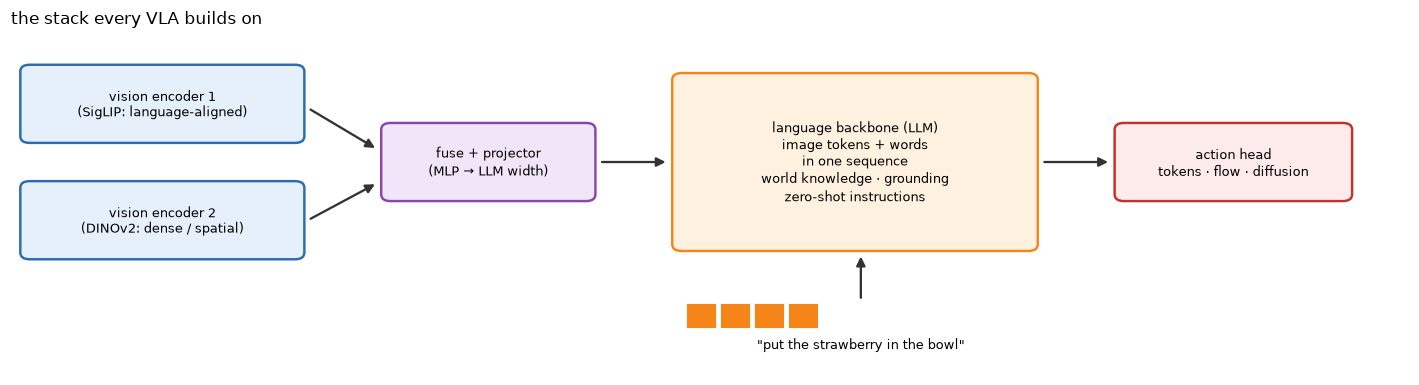

In [2]:
dg.fig_vla_backbone()

# Part 1: Vision encoders

A VLA's vision encoder turns pixels into a grid of **patch tokens** that the rest of the model reads. What those tokens *contain* depends on how the encoder was pre-trained. Two families matter:

* **Language-supervised / contrastive**: CLIP, **SigLIP**. Train an image tower and a text tower so that matching (image, caption) pairs agree. Features are *language-aligned* (they know "a red cube") but captions rarely say *where* or *how big*, so fine spatial detail is not rewarded.
* **Self-supervised**: **DINOv2**. No text: a student must match a teacher's output on augmented, partly masked views, at the image *and patch* level. Features are rich *locally* (every patch token describes its own content) and invariant to the nuisances the augmentations vary.

We pre-train a small version of each on the same rendered scenes, from scratch.

## Step 1: SigLIP: the pairwise sigmoid loss

CLIP's loss is a *softmax over the batch*: each image must pick its caption among all `B` captions. **SigLIP** (Zhai et al., 2023) replaces it by `B²` *independent binary* problems:

$$\mathcal L = -\frac1B \sum_{i=1}^{B}\sum_{j=1}^{B} \log \sigma\big(z_{ij}\,(t\,\langle \hat x_i,\hat y_j\rangle + b)\big),\qquad z_{ij}=\begin{cases}+1 & i=j\\ -1 & i\neq j\end{cases}$$

with learnable temperature `t` (init 10) and bias `b` (init −10, because almost all pairs are negatives). Nothing depends on the rest of the batch, so the loss needs no global normalisation: it scales to enormous batch sizes and works well at small ones.
Our captions mimic web alt-text: they list the colours present and, half the time, a **coarse relation** ("red left of blue") but *never coordinates*.

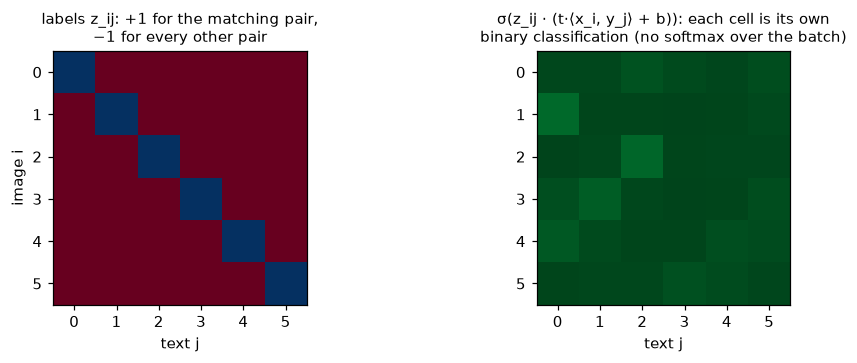

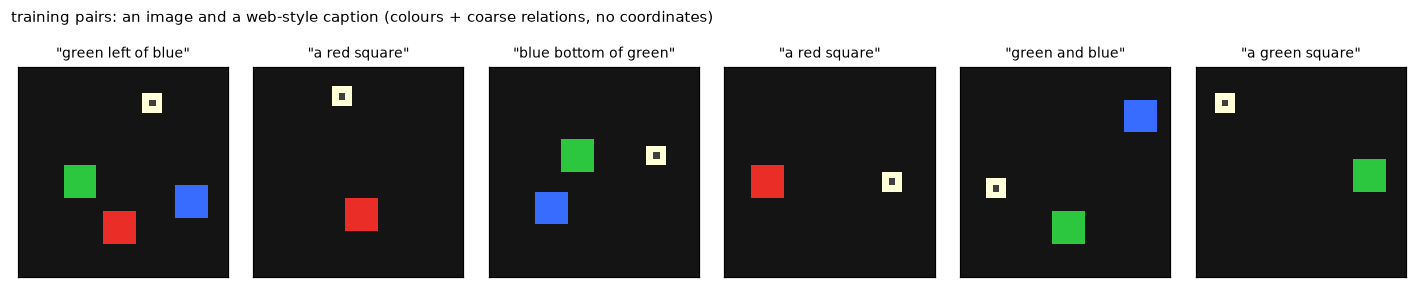

In [3]:
dg.fig_siglip_loss()
rng = np.random.default_rng(3)
demo_scenes = [world.sample_scene(rng, int(rng.integers(1, 4))) for _ in range(6)]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
for ax, s in zip(axes, demo_scenes):
    cap = scene_caption(s, rng)
    plots.show_image(ax, world.render(s.robot, s.objects), f'"{cap}"')
plt.suptitle("training pairs: an image and a web-style caption (colours + coarse relations, no coordinates)", x=0.01, ha="left", fontsize=10, y=1.03)
plt.tight_layout(); plt.show()

SigLIP-lite trained in 295 s, 130,624 vision + 87,232 text parameters


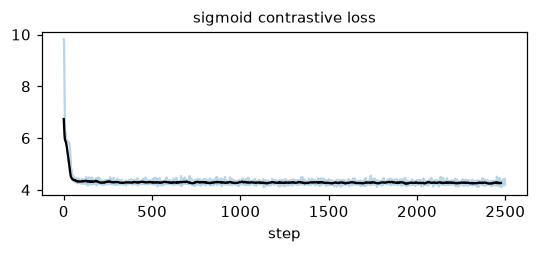

zero-shot colour presence (image vs. text 'a <colour> square', never trained as a classifier): 1.00


In [4]:
torch.manual_seed(0)
siglip = SigLIPLite(vocab)
slog = train_siglip(siglip, world, steps=2500)
print(f"SigLIP-lite trained in {slog.seconds:.0f} s, {sum(p.numel() for p in siglip.vision.parameters()):,} vision + {sum(p.numel() for p in siglip.text.parameters()):,} text parameters")
plt.figure(figsize=(5, 2.4)); plt.plot(slog.losses, alpha=0.3); plt.plot(np.convolve(slog.losses, np.ones(25) / 25, mode="valid"), color="k")
plt.title("sigmoid contrastive loss", fontsize=10); plt.xlabel("step"); plt.tight_layout(); plt.show()
print(f"zero-shot colour presence (image vs. text 'a <colour> square', never trained as a classifier): {zero_shot_colors(siglip, world):.2f}")

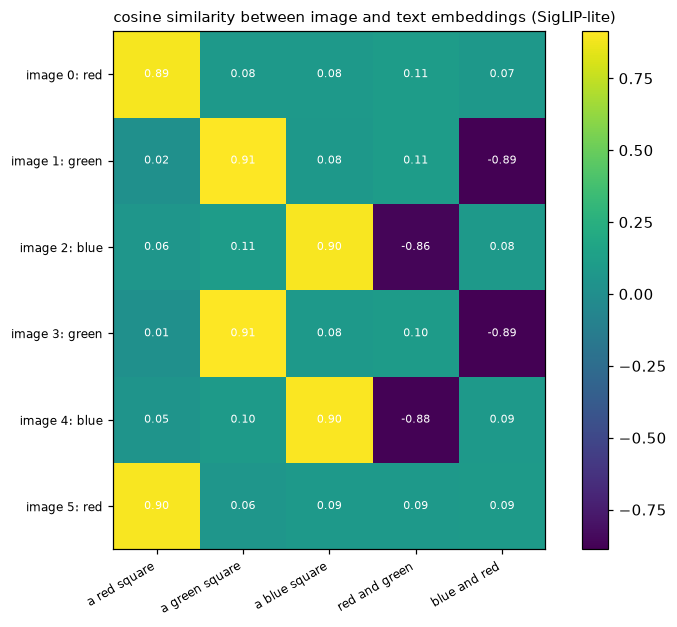

In [5]:
# the language-aligned embedding space: images vs words
rng = np.random.default_rng(11)
scenes1 = [world.sample_scene(rng, colors=[c]) for c in ("red", "green", "blue", "green", "blue", "red")]
imgs1 = torch.from_numpy(np.stack([world.render(s.robot, s.objects) for s in scenes1]))
words = ["a red square", "a green square", "a blue square", "red and green", "blue and red"]
with torch.no_grad():
    sim = (siglip.embed_images(imgs1) @ siglip.embed_text(words).T).numpy()
plots.plot_similarity(sim, [f"image {i}: {list(s.objects)[0]}" for i, s in enumerate(scenes1)], words, "cosine similarity between image and text embeddings (SigLIP-lite)")

The image of a red square is closest to "a red square": the model was never given colour *labels*, only captions, yet its image and text towers share a space where words and pictures line up. That is the power of language supervision:
**zero-shot, open-vocabulary** recognition.

## Step 2: DINOv2-style self-distillation

There are no captions at all. A **student** network and an **EMA teacher** (same architecture, weights = exponential moving average of the student's) see two differently augmented views of the same image. The student sees a copy with **random patches masked out**;
it must predict, at the *image* level (DINO) and at every *masked patch* (iBOT, which DINOv2 builds on), the teacher's output distribution over a set of learned prototypes. To prevent the trivial solution (everyone outputs the same thing) the teacher's targets are
**centred** (a running mean is subtracted) and **sharpened** (a low softmax temperature). Our augmentations are photometric only (brightness, contrast, noise): geometric crops would erase the position information we want the features to keep.

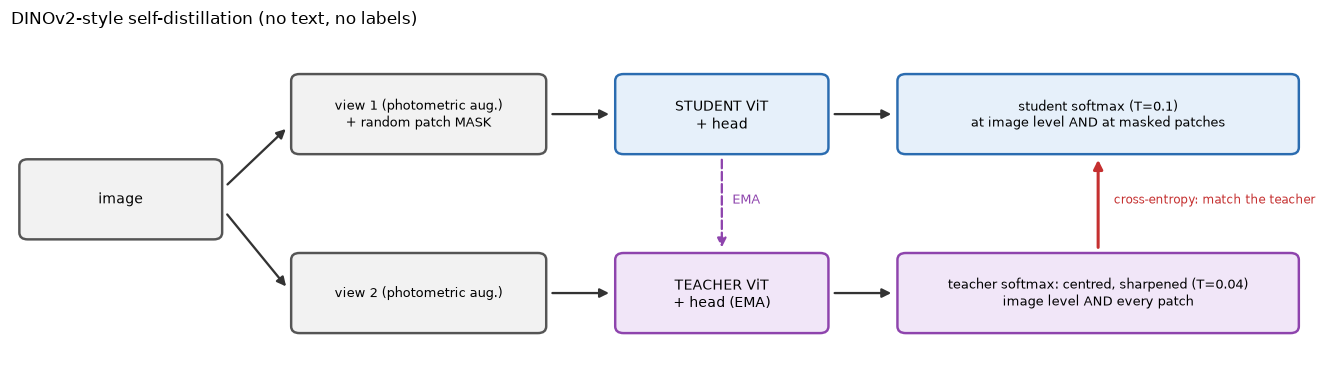

DINO-lite trained in 378 s
teacher ← m·teacher + (1 − m)·student (m = 0.99): True | teacher has no gradients: True


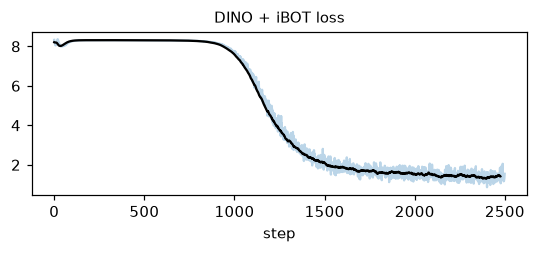

In [6]:
dg.fig_dino_scheme()
torch.manual_seed(0)
dino = DinoLite()
dlog = train_dino(dino, world, steps=2500)
print(f"DINO-lite trained in {dlog.seconds:.0f} s")
# verification: the teacher really is an exponential moving average of the student
before = [p.clone() for p in dino.teacher.parameters()]
with torch.no_grad():
    for p in dino.student.parameters():
        p.add_(0.1)
dino.ema_update()
ok = all(torch.allclose(t, dino.momentum * b + (1 - dino.momentum) * s, atol=1e-5) for t, b, s in zip(dino.teacher.parameters(), before, dino.student.parameters()))
with torch.no_grad():
    for p in dino.student.parameters():
        p.sub_(0.1)
print("teacher ← m·teacher + (1 − m)·student (m = %.2f):" % dino.momentum, ok, "| teacher has no gradients:", not any(p.requires_grad for p in dino.teacher.parameters()))
plt.figure(figsize=(5, 2.4)); plt.plot(dlog.losses, alpha=0.3); plt.plot(np.convolve(dlog.losses, np.ones(25) / 25, mode="valid"), color="k")
plt.title("DINO + iBOT loss", fontsize=10); plt.xlabel("step"); plt.tight_layout(); plt.show()

## Step 3: What did each encoder learn? Look inside

Take the patch tokens of each encoder, project them onto their three leading principal components, and show the result as an image: structure the encoder separates shows up as colour differences. Three encoders: a **random** (untrained) ViT as a baseline,
SigLIP-lite, and DINO-lite.

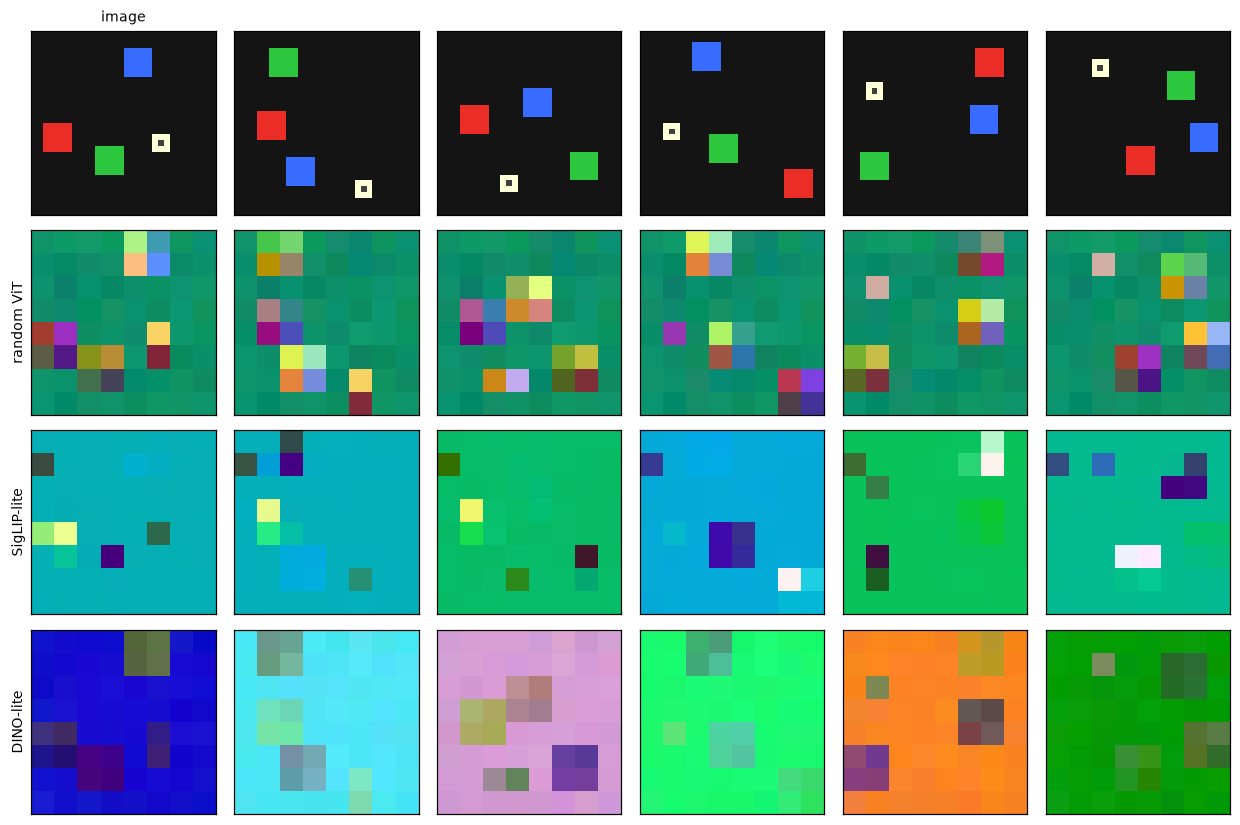

In [7]:
torch.manual_seed(0)
random_vit = ToyViT().eval()
encs = {"random ViT": random_vit, "SigLIP-lite": siglip.vision.eval(), "DINO-lite": dino.student.eval()}
rng = np.random.default_rng(21)
show_scenes = [world.sample_scene(rng, 3) for _ in range(6)]
show_imgs = torch.from_numpy(np.stack([world.render(s.robot, s.objects) for s in show_scenes]))
plots.plot_patch_pca(encs, show_imgs)

**Reading the rows.** (The *hue* of each map is arbitrary: PCA picks a different basis per image, so the background colour changes from image to image. What matters is which patches *stand out* and how coherently.)
In all three the objects are visible, but not equally. The **random** ViT turns every object into a small multi-hued cluster, mostly echoing the raw pixel values of its patches. **DINO-lite** gives the most consistent picture: the object patches share a few hues, clearly apart from the background and the robot
dot, which is what a *patch-level* objective rewards (each patch token must predict its own teacher token). **SigLIP-lite** shows objects as isolated bright or dark patches on a flat background: its only training signal is *one pooled embedding per image* ("which colours are here"), so nothing forces individual patch tokens to keep local detail,
and the model is free to concentrate the information in a few tokens.

## Step 4: A semantic probe under a visual shift

PCA is suggestive; a measurement is better. We fit a **linear probe** on the *pooled* feature to say whether a blue object is present, training on clean images, and then test on images with a *lighting / camera change* (per-channel gain, brightness offset, noise).
A good encoder is not only accurate on clean data but stays accurate when the appearance shifts. (The probe is a single linear layer, so any difference is in the features.)

random ViT   shift 0.0: 1.00  shift 0.5: 0.60  shift 1.0: 0.56  shift 1.5: 0.56  shift 2.0: 0.56


SigLIP-lite  shift 0.0: 1.00  shift 0.5: 1.00  shift 1.0: 1.00  shift 1.5: 0.99  shift 2.0: 0.94


DINO-lite    shift 0.0: 1.00  shift 0.5: 1.00  shift 1.0: 1.00  shift 1.5: 0.96  shift 2.0: 0.88


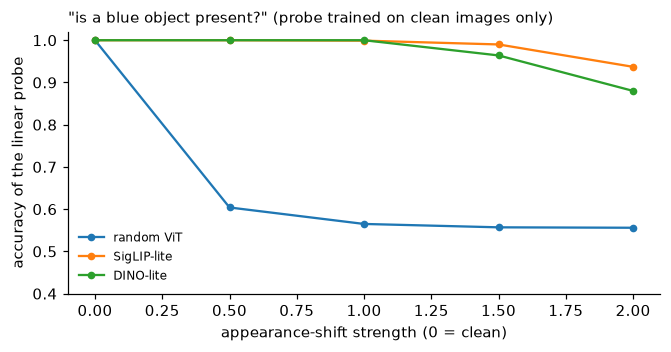

In [8]:
strengths = (0.0, 0.5, 1.0, 1.5, 2.0)
probe_res = {}
for name, enc in encs.items():
    probe_res[name] = [semantic_probe(lambda x: enc(x), world, color="blue", test_transform=(None if s == 0 else (lambda x, s=s: appearance_shift(x, s)))) for s in strengths]
    print(f"{name:12s} " + "  ".join(f"shift {s}: {a:.2f}" for s, a in zip(strengths, probe_res[name])), flush=True)
plots.curves(list(strengths), probe_res, "appearance-shift strength (0 = clean)", "accuracy of the linear probe", '"is a blue object present?" (probe trained on clean images only)', ylim=(0.4, 1.02))

All three encoders are *perfect* on clean images (flat-coloured squares are easy to read from raw pixels), but under a visual shift they separate:

* the **random** features were never taught to be invariant to anything, so a probe fitted on clean data falls to chance (0.56 = always answering "no blue") at the weakest shift;
* **SigLIP-lite** and **DINO-lite** both hold up, for different reasons. SigLIP's captions pair the *same words* with images that differ in everything else, so features that track the colour *identity* are rewarded; DINO's augmentations explicitly train invariance to brightness / contrast / noise.
  On this *global semantic* question SigLIP-lite is in fact the more robust of the two at the strongest shifts, which is the "language supervision = semantics" half of the story. The other half (where things are) comes next.

## Step 5: Encoders inside a policy: frozen, then shifted

Now the question that matters for a VLA. We plug each encoder, **frozen**, into the same policy (early fusion, the OpenVLA layout: patch tokens → MLP projector → a small trainable transformer together with the instruction → action expert), train it on **clean** images, and evaluate on clean *and* appearance-shifted images,
for both instruction families. We also build the **fused** encoder (SigLIP-lite ‖ DINO-lite, concatenated per patch) as in OpenVLA.

In [9]:
def train_policy(vision, vision_width, fusion="early", steps=4000, demos=None, seed=0):
    torch.manual_seed(seed)
    m = FusionPolicy(copy.deepcopy(vision), vision_width, FusionConfig(fusion=fusion), vocab)
    d = EmbodiedMixture([EmbodiedSource(world, demos if demos is not None else colour_demos + side_demos, EMBODIMENTS["point2d"])])
    h = PiTrainer(m, d, batch_size=64, lr=2e-3, grad_clip=10.0).fit(steps)
    return m, h

def evaluate_policy(m, strength=1.0):
    out = {}
    for tag, scen in (("colour", colour_scen), ("side", side_scen)):
        out[tag] = ev.run(lambda b: m.sample_actions(b), scen).success_rate
        out[tag + " (shifted)"] = ev.run(lambda b: m.sample_actions(b.replace(images=appearance_shift(b.images, strength))), scen).success_rate
    return out

backbones = {"random (frozen)": (random_vit, 64), "SigLIP-lite (frozen)": (siglip.vision.eval(), 64), "DINO-lite (frozen)": (dino.student.eval(), 64),
             "fused SigLIP ‖ DINO (frozen)": (FusedVision(siglip.vision.eval(), dino.student.eval()), 128)}
enc_results = {}
for name, (vision, w) in backbones.items():
    m, h = train_policy(vision, w)
    enc_results[name] = evaluate_policy(m)
    print(f"{name:30s} {h.seconds:4.0f} s  " + "  ".join(f"{k} {v:.2f}" for k, v in enc_results[name].items()), flush=True)

random (frozen)                 220 s  colour 0.99  colour (shifted) 0.48  side 0.97  side (shifted) 0.35


SigLIP-lite (frozen)            194 s  colour 0.64  colour (shifted) 0.35  side 0.62  side (shifted) 0.33


DINO-lite (frozen)              323 s  colour 0.95  colour (shifted) 0.90  side 0.90  side (shifted) 0.85


fused SigLIP ‖ DINO (frozen)    468 s  colour 0.98  colour (shifted) 0.95  side 0.99  side (shifted) 0.89


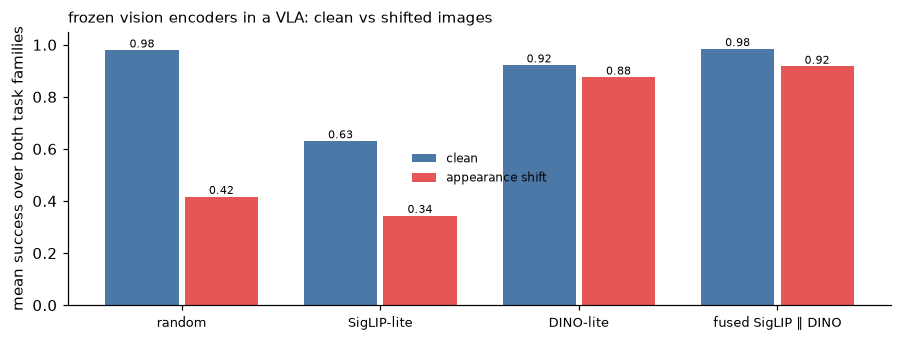

In [10]:
names = list(enc_results)
plots.grouped_bars({n.replace(" (frozen)", ""): {"clean": np.mean([enc_results[n]["colour"], enc_results[n]["side"]]), "appearance shift": np.mean([enc_results[n]["colour (shifted)"], enc_results[n]["side (shifted)"]])} for n in names},
                   "mean success over both task families", "frozen vision encoders in a VLA: clean vs shifted images", colors=["#4c78a8", "#e45756"])

**What to take from this.** (1) A frozen *random* ViT is excellent on the training distribution, because this toy world is trivially readable from pixels, but it **collapses under a visual shift** (≈ 0.9-1.0 → 0.35-0.5): a policy is only as robust as the features it reads.
(2) The **DINO-style** encoder, trained with photometric augmentations and patch-level targets, keeps nearly all of its success under shift (0.95 → 0.90, 0.90 → 0.85). (3) The **SigLIP-style** encoder is the *worst policy encoder even on clean images* (0.64 / 0.62), although it was the most robust in the linear probe of Step 4: its pooled,
global embedding says *what* is in the picture but not *where* (our captions never contain coordinates), and a manipulation policy needs *where*. This is the toy version of the OpenVLA / Prismatic finding that SigLIP alone is not enough. (4) The **fused** encoder is the best overall: it matches DINO's spatial precision on clean images (0.98 / 0.99) and is
the most robust on the colour task under shift (0.95), taking the best of both streams. In real OpenVLA the SigLIP stream contributes what a toy world has no room for: web-scale *semantic* knowledge ("what is a spatula"), alongside DINOv2's spatial detail.

# Part 2: The language backbone

## Step 6: What does the LLM bring?

The language model in a VLA provides **language grounding**, **zero-shot generalisation to new instructions** and **world knowledge transferred from the web**. RT-2 states the recipe plainly: *co-fine-tune* a pre-trained VLM on robot action tokens **and** on the original vision-language data, so that the web knowledge
isn't overwritten while the actions are learned. Its Table 6 compares **training from scratch**, **fine-tuning on robot data only**, and **co-fine-tuning**, at two sizes (5B / 55B), on generalisation to unseen objects, backgrounds and environments.

We reproduce the *structure* of that experiment. The knowledge to transfer is **vocabulary**: the VQA data names objects with synonyms (`crimson` = red, `emerald` = green, `azure` = blue); the robot demonstrations only ever say `go to red`. A policy that follows **`go to crimson`**
must be using language knowledge that did not come from robot data. The policy is RT-2-style: the VLM itself emits action tokens (`AutoregressiveActionPolicy`).

In [11]:
vocab_ar = PiVocabulary(fast_size=256)
sizes = {"small": VLMConfig(width=32, depth=3, num_heads=2, head_dim=16), "medium": VLMConfig(width=64, depth=4, num_heads=4, head_dim=16), "large": VLMConfig(width=96, depth=6, num_heads=6, head_dim=16)}
vlms = {}
for sz, cfg in sizes.items():
    torch.manual_seed(0)
    v = ToyVLM(cfg, vocab_ar)
    p = VLMPretrainer(v, world, synonym_prob=0.3)
    p.fit(1500)
    vlms[sz] = v
    print(f"{sz:6s} VLM ({sum(q.numel() for q in v.parameters()):7,} parameters) pre-trained on VQA incl. synonyms in {p.history.seconds:3.0f} s, answer accuracy {np.mean(p.history.accuracy[-50:]):.2f}", flush=True)
probe_q = VLMPretrainer(vlms["large"], world)
imgs, _, _ = probe_q.sample(100)
agree = {}
for syn, plain in (("crimson", "red"), ("emerald", "green"), ("azure", "blue")):
    a_syn, a_plain = probe_q.ask(imgs, f"where is {syn}"), probe_q.ask(imgs, f"where is {plain}")
    agree[f"{syn} / {plain}"] = float(np.mean([x == y for x, y in zip(a_syn, a_plain)]))
print("the pre-trained VLM answers 'where is <synonym>?' exactly like 'where is <colour>?' on this fraction of 100 scenes:", {k: round(v, 2) for k, v in agree.items()})

small  VLM ( 62,624 parameters) pre-trained on VQA incl. synonyms in  76 s, answer accuracy 0.87


medium VLM (235,968 parameters) pre-trained on VQA incl. synonyms in 104 s, answer accuracy 0.93


large  VLM (673,824 parameters) pre-trained on VQA incl. synonyms in 148 s, answer accuracy 0.84


the pre-trained VLM answers 'where is <synonym>?' exactly like 'where is <colour>?' on this fraction of 100 scenes: {'crimson / red': 1.0, 'emerald / green': 0.98, 'azure / blue': 0.98}


## Step 7: From scratch vs fine-tune vs co-fine-tune, at three sizes

The robot data is the three-object colour task (4000 demonstrations, plain colour words only). Each regime trains the same autoregressive policy for the same number of steps:

* **from scratch**: a randomly initialised VLM of the same size, robot data only;
* **fine-tune**: start from the VQA-pre-trained VLM (which knows the synonyms), robot action tokens only;
* **co-fine-tune** (RT-2's recipe): start from the pre-trained VLM and train on robot action tokens **mixed 2:1 with the VQA data** (synonyms included).

We evaluate on `go to <colour>` (seen wording) and on `go to <synonym>` (*never* in the robot data), 96 scenes each. (To keep the runtime down we run all three regimes for `small` and `large`, and co-fine-tuning for `medium`.)

In [12]:
ar_data = EmbodiedMixture([EmbodiedSource(world, colour_demos, EMBODIMENTS["point2d"], chunk_size=1)])
ev1 = EmbodiedEvaluator(world, 1, 1, 50)
seen_scen, novel_scen = colour_scenarios_three(gen, 96, 123), synonym_scenarios(gen, 96, 321)
lang = {}
plan = [("small", r) for r in ("scratch", "fine-tune", "co-fine-tune")] + [("medium", "co-fine-tune")] + [("large", r) for r in ("scratch", "fine-tune", "co-fine-tune")]
for sz, regime in plan:
    torch.manual_seed(0)
    init = ToyVLM(sizes[sz], vocab_ar) if regime == "scratch" else vlms[sz]
    m = AutoregressiveActionPolicy(init, ARConfig(chunk_size=1))
    sampler = VLMPretrainer(vlms[sz], world, synonym_prob=0.3, seed=5).sample
    data = make_cofine_tune_data(ar_data, sampler, 0.5) if regime == "co-fine-tune" else ar_data
    h = PiTrainer(m, data, batch_size=64, lr=2e-3, grad_clip=10.0).fit(3000); m.eval()
    lang[(sz, regime)] = dict(seen=ev1.run(lambda b: m.sample_actions(b), seen_scen).success_rate, novel=ev1.run(lambda b: m.sample_actions(b), novel_scen).success_rate, params=m.parameter_counts()["total"])
    print(f"{sz:6s} {regime:13s} {h.seconds:4.0f} s  seen {lang[(sz, regime)]['seen']:.2f}  novel synonyms {lang[(sz, regime)]['novel']:.2f}", flush=True)

small  scratch        133 s  seen 0.01  novel synonyms 0.01


small  fine-tune      142 s  seen 0.24  novel synonyms 0.25


small  co-fine-tune   182 s  seen 0.22  novel synonyms 0.18


medium co-fine-tune   442 s  seen 0.95  novel synonyms 0.88


large  scratch        439 s  seen 0.00  novel synonyms 0.02


large  fine-tune      267 s  seen 0.16  novel synonyms 0.18


large  co-fine-tune   317 s  seen 0.86  novel synonyms 0.77


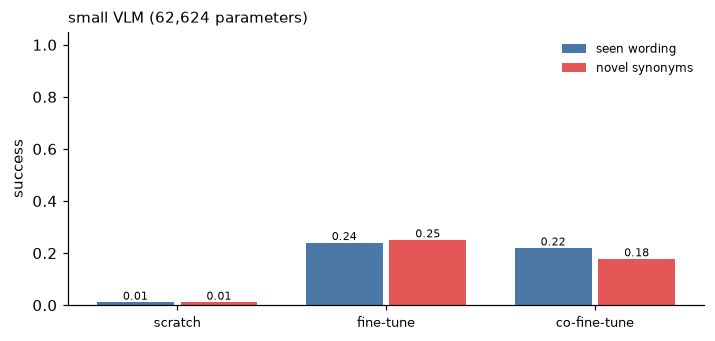

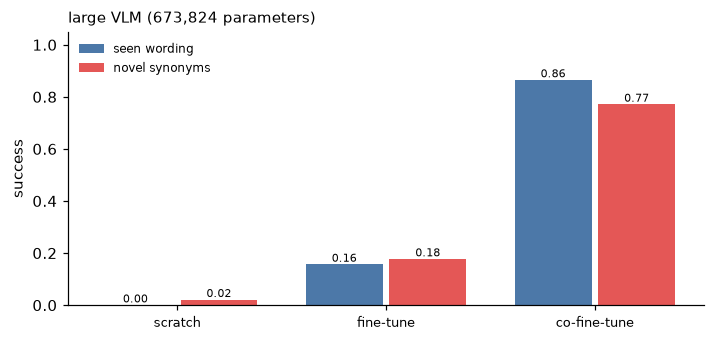

RT-2 Table 6 for comparison (average generalisation success, %):
   5B  from scratch 9 | fine-tune 42 | co-fine-tune 44        55B  fine-tune 52 | co-fine-tune 63


In [13]:
for sz in ("small", "large"):
    plots.grouped_bars({r: {"seen wording": lang[(sz, r)]["seen"], "novel synonyms": lang[(sz, r)]["novel"]} for r in ("scratch", "fine-tune", "co-fine-tune")}, "success", f"{sz} VLM ({lang[(sz, 'scratch')]['params']:,} parameters)", colors=["#4c78a8", "#e45756"])
print("RT-2 Table 6 for comparison (average generalisation success, %):")
print("   5B  from scratch 9 | fine-tune 42 | co-fine-tune 44        55B  fine-tune 52 | co-fine-tune 63")

**The pattern matches RT-2's Table 6 where the model has the capacity.** (1) **From scratch is by far the worst** (≈ 0.00-0.01 at both sizes): with random weights the model cannot ground language in 3000 steps of robot data (RT-2: *"training a very large model from scratch results in a very poor performance even for the 5B model"*).
(2) **Fine-tuning a pre-trained VLM on robot data only is better than scratch but poor** (0.16-0.25): the robot data has only plain colour words and, more importantly, this regime overwrites the VLM's knowledge while fitting the actions. (3) **Co-fine-tuning** keeps the VLM's competence and reaches 0.86-0.95 on the plain instructions and 0.77-0.88 on the synonym instructions it has never been shown with robot data,
for the `medium` and `large` models (RT-2: *"co-fine-tuning … results in a better generalization performance than simply fine-tuning it with robotic data … allows the model to not forget its previous concepts"*). The **small** model (62K parameters) cannot hold both the actions and the language knowledge, and gains nothing from co-fine-tuning (0.22 / 0.18): *co-fine-tuning needs capacity*.
Note also that the synonym score trails the seen-wording score by 5-10 points: some of what the VLM knows is lost in transfer, the usual price of a gap between pre-training and robot data.

## Step 8: Does the LLM need to stay large?

RT-2's other axis is size. Their answer: bigger is better for generalisation (5B → 55B: 44 → 63 co-fine-tuned), with the cost that the 55B model runs at 1-3 Hz instead of 5 Hz. We read the same axis off our three sizes (co-fine-tuned):

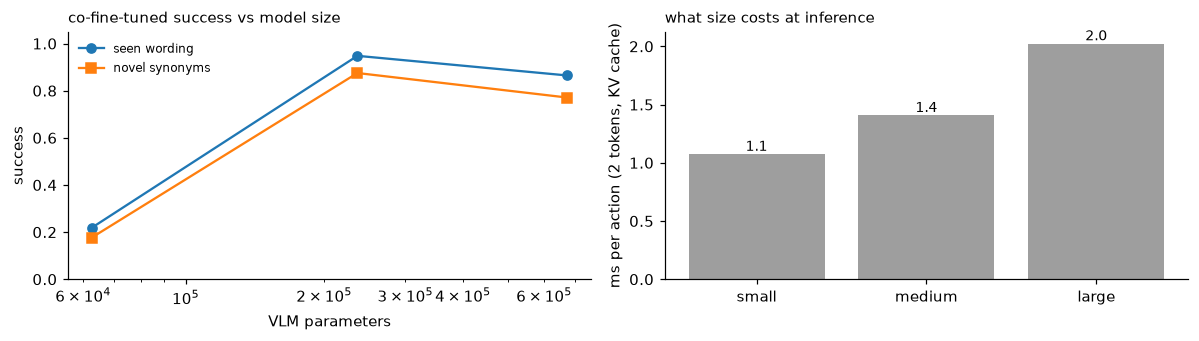

{'small': {'params': '62,624', 'seen': 0.21875, 'novel': 0.17708333333333334}, 'medium': {'params': '235,968', 'seen': 0.9479166666666666, 'novel': 0.875}, 'large': {'params': '673,824', 'seen': 0.8645833333333334, 'novel': 0.7708333333333334}}


In [14]:
sz_rows = {sz: lang[(sz, "co-fine-tune")] for sz in ("small", "medium", "large")}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), facecolor="white")
xs = [sz_rows[s]["params"] for s in sz_rows]
axes[0].plot(xs, [sz_rows[s]["seen"] for s in sz_rows], "o-", label="seen wording"); axes[0].plot(xs, [sz_rows[s]["novel"] for s in sz_rows], "s-", label="novel synonyms")
axes[0].set_xscale("log"); axes[0].set_xlabel("VLM parameters"); axes[0].set_ylabel("success"); axes[0].set_ylim(0, 1.05); axes[0].legend(fontsize=8, frameon=False); axes[0].set_title("co-fine-tuned success vs model size", fontsize=10, loc="left")
lat = {}
one_b = ar_data.sample(1, np.random.default_rng(2))
for sz in sz_rows:
    mm = AutoregressiveActionPolicy(vlms[sz], ARConfig(chunk_size=1)).eval()
    mm.generate_cached(one_b); t0 = time.perf_counter()
    for _ in range(15):
        mm.generate_cached(one_b)
    lat[sz] = 1000 * (time.perf_counter() - t0) / 15
axes[1].bar(list(lat), list(lat.values()), color="#9e9e9e")
for i, v in enumerate(lat.values()):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
axes[1].set_ylabel("ms per action (2 tokens, KV cache)"); axes[1].set_title("what size costs at inference", fontsize=10, loc="left")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print({s: dict(params=f"{r['params']:,}", seen=r["seen"], novel=r["novel"]) for s, r in sz_rows.items()})

In our toy, success rises from the `small` model (0.22) to the `medium` model (0.95) and then does **not** rise further at `large` (0.86): at a fixed budget of 3000 steps a 3× bigger model is not trained to convergence, and the pre-training stage (1500 steps) was the same for all sizes. So once the model has *enough* capacity for the task, extra size bought nothing here,
while the latency panel shows its cost (each step up in width/depth costs time per action; for a real 7B-55B VLM that is the difference between 1 Hz and 6 Hz). This is the shape of RT-2's finding that the 5B → 55B gain is real but is bought with latency, and of the field's move to **small VLMs (0.5-3B) with a separate action expert** (SmolVLA, π0, GR00T): manipulation itself is a small
problem next to language, so a big LLM mostly pays for **breadth of knowledge** (new objects, instructions, reasoning) rather than for motor skill, and chunked continuous action heads (Part 1 of the action notebook) decouple the *action* rate from the LLM's token rate.

# Part 3: Cross-modal fusion

## Step 9: Where do vision and language meet?

Three architectures, differing only in *when the modalities are allowed to interact*:

* **early fusion** (RT-2, OpenVLA, π0): image tokens (after a projector into the LLM's embedding space) and word tokens share **one transformer**; every layer lets every image token attend to every word and vice versa;
* **late fusion**: separate vision and text towers that never see each other; only the action expert's cross-attention over the *concatenation* joins them;
* **pooled / global fusion** (CLIP-style): each modality is reduced to **one vector** and an MLP mixes the two vectors.

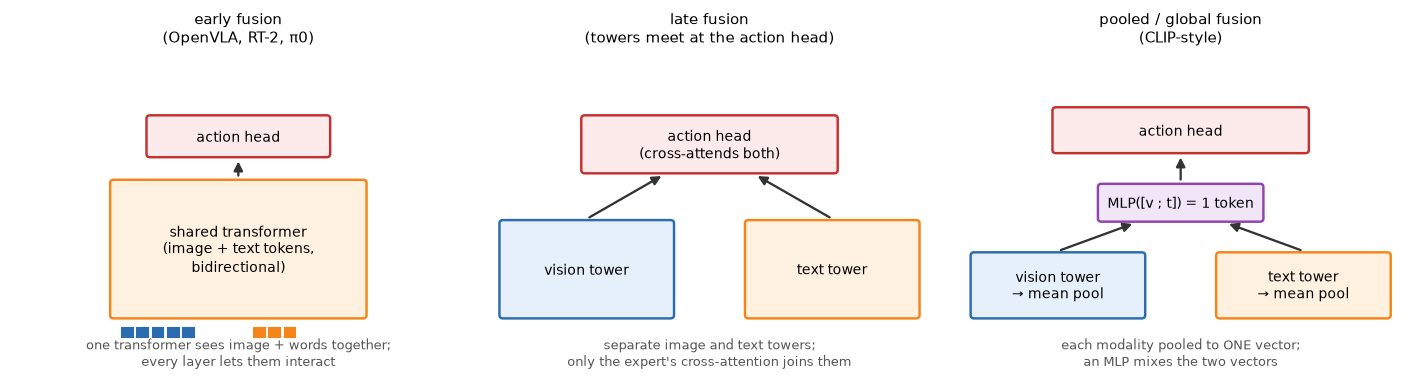

In [15]:
dg.fig_fusion_types()

We train the three variants with the same frozen DINO-lite vision encoder, the same flow-matching action expert, the same data (colour + side instructions, 6000 demonstrations) and the same steps, then test both task families. The **colour** task needs *binding* ("the word red picks the red object"),
the **side** task needs *comparison between objects* (which is leftmost?).

early   fusion ( 612 s, 257,730 trainable params): colour task 0.98  side task 0.97  | final flow loss 0.028


late    fusion ( 770 s, 298,818 trainable params): colour task 0.21  side task 0.64  | final flow loss 0.096


pooled  fusion ( 622 s, 146,882 trainable params): colour task 0.09  side task 0.15  | final flow loss 0.170


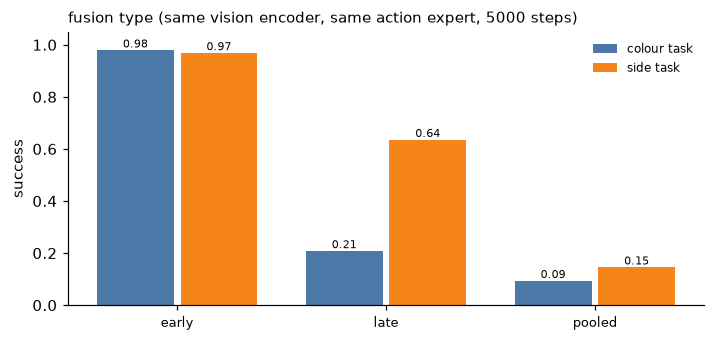

In [16]:
fusion_results = {}
for fusion in ("early", "late", "pooled"):
    m, h = train_policy(dino.student.eval(), 64, fusion=fusion, steps=5000)
    out = {tag: ev.run(lambda b: m.sample_actions(b), scen).success_rate for tag, scen in (("colour task", colour_scen), ("side task", side_scen))}
    fusion_results[fusion] = dict(out, trainable=m.parameter_counts()["trainable"], flow=float(np.mean(h.series("flow")[-100:])))
    print(f"{fusion:7s} fusion ({h.seconds:4.0f} s, {fusion_results[fusion]['trainable']:,} trainable params): " + "  ".join(f"{k} {v:.2f}" for k, v in out.items()) + f"  | final flow loss {fusion_results[fusion]['flow']:.3f}", flush=True)
    if fusion == "early":
        early_model = m
plots.grouped_bars({f: {"colour task": fusion_results[f]["colour task"], "side task": fusion_results[f]["side task"]} for f in fusion_results}, "success", "fusion type (same vision encoder, same action expert, 5000 steps)", colors=["#4c78a8", "#f58518"])

**What to take from this.**

* **Pooled fusion fails**: collapsing the image to one mean vector throws away *where* things are, so the policy cannot find the target: this is the CLIP-style limitation (a global embedding says what is in the picture, not where).
* **Late fusion is much harder to learn** (the same budget gives a fraction of early fusion's success; in a longer run it improves but stays behind): to follow "go to red" the action expert must first *retrieve* the word from the text tower, and only then use it to select image tokens;
  two cross-attention hops, learned from action loss alone, with no direct signal about which word goes with which object.
* **Early fusion works**: in a joint transformer the word token and the image tokens attend to each other directly, so "red" can *pick out* the red object's tokens in the first layers and the rest of the stack carries the result to the action expert. That is why RT-2, OpenVLA and π0 all
  fuse early, and why they reuse a pre-trained LLM, which already knows how to bind words to things.

## Step 10: Looking inside early fusion: does the word attend to its object?

In the early-fusion model every layer of the joint transformer has attention weights between the instruction's colour word and the image tokens. We recompute them for a few scenes and show, for each layer, which image tokens the colour word attends to (averaged over heads):

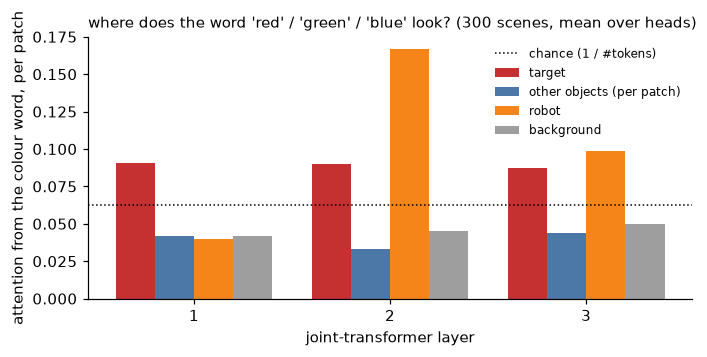

{'target': [0.091, 0.09, 0.088], 'other': [0.042, 0.033, 0.044], 'robot': [0.04, 0.167, 0.099], 'background': [0.042, 0.045, 0.05]} chance 0.062


In [17]:
breakdown = attention_breakdown(early_model, world, colour_scenarios_three(gen, 300, 999))
layers = np.arange(1, len(breakdown["target"]) + 1)
fig, ax = plt.subplots(figsize=(6.4, 3.3))
width = 0.2
for j, (key, col) in enumerate((("target", "#c53030"), ("other", "#4c78a8"), ("robot", "#f58518"), ("background", "#9e9e9e"))):
    ax.bar(layers + (j - 1.5) * width, breakdown[key], width, label=key if key != "other" else "other objects (per patch)", color=col)
ax.axhline(breakdown["chance"], color="k", ls=":", lw=1, label="chance (1 / #tokens)")
ax.set_xticks(layers); ax.set_xlabel("joint-transformer layer"); ax.set_ylabel("attention from the colour word, per patch")
ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("where does the word 'red' / 'green' / 'blue' look? (300 scenes, mean over heads)", fontsize=10, loc="left")
plt.tight_layout(); plt.show()
print({k: np.round(v, 3).tolist() for k, v in breakdown.items() if k != "chance"}, "chance", round(breakdown["chance"], 3))

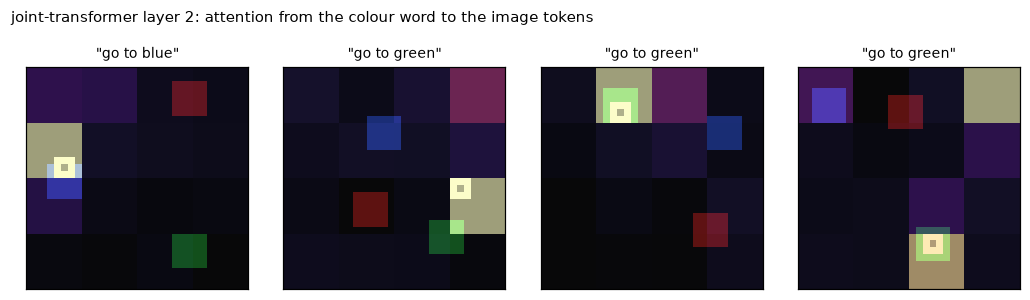

In [18]:
# the same attention as a picture, for the layer where the target-vs-other contrast is strongest
best = int(np.argmax(breakdown["target"] / (breakdown["other"] + 1e-9)))
b = EmbodiedMixture([EmbodiedSource(world, colour_demos[:40], EMBODIMENTS["point2d"])]).sample(4, np.random.default_rng(4))
with torch.no_grad():
    maps, n_img = word_to_image_attention(early_model, b)
g = int(np.sqrt(n_img))
fig, axes = plt.subplots(1, 4, figsize=(9.5, 2.6))
for j, ax in enumerate(axes):
    plots.show_image(ax, b.images[j], f'"{b.task[j]}"')
    ax.imshow(maps[best][j].reshape(g, g).numpy(), cmap="magma", alpha=0.6, extent=(-0.5, 31.5, 31.5, -0.5), interpolation="nearest")
plt.suptitle(f"joint-transformer layer {best + 1}: attention from the colour word to the image tokens", x=0.01, ha="left", fontsize=9.5, y=1.03)
plt.tight_layout(); plt.show()

**Reading the bars** (chance is `1/16 = 0.062` per patch). In **every layer** the colour word looks at the **target object's patch about twice as much as at any other object** (≈ 0.09 against 0.03-0.04 per patch, and above chance), which is "red" picking out the red square. It is not the only thing it looks at: in the **middle layer** the largest share goes to the **robot's patch** (0.17: where the action starts), and the background gets
little. So the word binds to the right object *and* to the arm, the two things an action chunk is computed from (this is one trained network, one seed: the layer where the robot attention peaks can differ between runs; a stable finding is *target ≫ other objects*). The picture above shows the same attention as a heat-map over the scene for the layer where the contrast is strongest.
In *late* fusion this step has no home; in *pooled* fusion it is impossible. This is the mechanism by which an LLM backbone "grounds" language in a VLA.

## Step 11: The real VLAs, side by side

| model | vision encoder(s) | language backbone | fusion | action head |
|---|---|---|---|---|
| RT-2 | ViT-22B (PaLI-X) / ViT-4B (PaLM-E) | PaLI-X 5B / 55B, PaLM-E 12B | early (image tokens → LLM) | 256-bin tokens, 8 per step |
| OpenVLA | DINOv2 ‖ SigLIP (fused, channel-concat) | Llama 2 7B | early (MLP projector → LLM) | 256 quantile-bin tokens, 7 per step |
| π0 | SigLIP (PaliGemma) | Gemma 2B (PaliGemma 3B) | early, with a separate **action expert** | flow matching, 50-step chunks |
| SmolVLA | SigLIP (SmolVLM-2) | SmolLM2, first half of the layers | early (VLM) + **cross-attention** to the expert | flow matching, 50-step chunks |
| GR00T N1 | SigLIP-2 (Eagle-2) | SmolLM2, 12th-layer features | early in the VLM; the DiT *cross-attends* | flow matching, 16-step chunks |

**Take-aways.** (1) The vision encoder decides what the policy can *see* and how it breaks under a visual shift: self-supervised dense features (DINOv2) buy spatial detail and robustness, language-supervised features (SigLIP) buy semantics, and fusing both is what OpenVLA
found best. (2) The language backbone is where **knowledge transfer** lives: pre-training is non-negotiable (from scratch fails), *how you fine-tune* matters (co-fine-tuning preserves what fine-tuning erases), and size adds generalisation at a latency price. (3) Fusion should be
**early** if the model has to ground words in specific objects; late and pooled fusion either need much more training or discard the spatial information.

### 🧪 Exercises
1. Give DINO-lite a **geometric** augmentation (random shifts of a few pixels) and redo the localisation probe in `vla_foundations.probes`: which property do you trade for which?
2. In Step 5 *unfreeze* the vision encoder (`FusionConfig(train_vision=True)`): does the random encoder catch up on clean images? Does it stay fragile under shift?
3. Add a **fourth** synonym-style instruction ("go to the leftmost") to the VQA data only and test whether the co-fine-tuned policy follows it.
4. In Step 9 run late fusion for 10000 steps (`train_policy(..., fusion="late", steps=10000)`): how much of the gap to early fusion closes?
5. Make the expert read **all** joint-transformer layers (as SmolVLA does) instead of only the last one and compare.